# Kelly Criterion Analysis

**Optimal bet sizing based on edge and probability**

Formula: f = (bp - q) / b
- b = odds - 1
- p = model probability
- q = 1 - p

Author: Ecem Yildirim  
Date: March 2026

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [28]:
# Load data
merged = pd.read_csv('../data/streamlit_data/betting_df_for_streamlit.csv')
merged_unique = merged.drop_duplicates(subset='match_id', keep='first').copy()

print(f"Loaded {len(merged_unique):,} unique matches")

Loaded 2,695 unique matches


## 1. Calculate Kelly Fractions

In [29]:
def calculate_kelly(model_prob, market_prob):
    """
    Calculate Kelly fraction for a bet.
    
    Returns:
    - Kelly fraction (0 to 1, where 1 = 100% of bankroll)
    - Capped at 0.25 (25% max per bet for safety)
    """
    if market_prob <= 0 or market_prob >= 1:
        return 0
    
    # Convert market prob to decimal odds
    decimal_odds = 1 / market_prob
    b = decimal_odds - 1  # Net odds
    
    p = model_prob  # Our estimate of win probability
    q = 1 - p
    
    # Kelly formula
    kelly = (b * p - q) / b
    
    # Only bet if positive edge
    if kelly <= 0:
        return 0
    
    # Cap at 25% for safety
    return min(kelly, 0.25)

# Calculate Kelly for all matches
merged_unique['kelly_fraction'] = merged_unique.apply(
    lambda row: calculate_kelly(row['model_prob'], row['market_prob']),
    axis=1
)

print("\n" + "="*80)
print("KELLY FRACTION STATISTICS")
print("="*80)

positive_kelly = merged_unique[merged_unique['kelly_fraction'] > 0]
print(f"\nMatches with positive Kelly: {len(positive_kelly):,} ({len(positive_kelly)/len(merged_unique)*100:.1f}%)")
print(f"\nKelly fraction distribution:")
print(positive_kelly['kelly_fraction'].describe())


KELLY FRACTION STATISTICS

Matches with positive Kelly: 1,180 (43.8%)

Kelly fraction distribution:
count    1180.000000
mean        0.182320
std         0.084606
min         0.000627
25%         0.108068
50%         0.250000
75%         0.250000
max         0.250000
Name: kelly_fraction, dtype: float64


## 2. Top Kelly Recommendations

In [30]:
# Filter for significant Kelly bets (> 5%)
kelly_bets = merged_unique[merged_unique['kelly_fraction'] > 0.05].copy()

print(f"\nBets with Kelly > 5%: {len(kelly_bets):,}")
print(f"\nTop 10 Kelly Recommendations:")
print("-"*100)
print(f"{'Date':<12s} {'Matchup':<40s} {'Model':<8s} {'Market':<8s} {'Edge':<8s} {'Kelly':<8s} {'Outcome'}")
print("-"*100)

top_kelly = kelly_bets.nlargest(10, 'kelly_fraction')
for _, row in top_kelly.iterrows():
    matchup = f"{row['Player'][:15]} vs {row['Opponent'][:15]}"
    outcome = "✓ WON" if row['Won'] == 1 else "✗ LOST"
    print(f"{row['Date']:<12s} {matchup:<40s} {row['model_prob']:>6.1%} {row['market_prob']:>6.1%} "
          f"{row['edge']:>6.1%} {row['kelly_fraction']:>6.1%} {outcome}")


Bets with Kelly > 5%: 1,034

Top 10 Kelly Recommendations:
----------------------------------------------------------------------------------------------------
Date         Matchup                                  Model    Market   Edge     Kelly    Outcome
----------------------------------------------------------------------------------------------------
2024-01-01   Shelton B. vs Safiullin R.                85.0%  61.3%  23.7%  25.0% ✗ LOST
2024-01-01   Purcell M. vs Rune H.                     54.6%  27.4%  27.2%  25.0% ✗ LOST
2024-01-02   Etcheverry T. vs Machac T.                51.2%  33.1%  18.0%  25.0% ✗ LOST
2024-01-03   Kotov P. vs Musetti L.                    69.9%  46.1%  23.8%  25.0% ✓ WON
2024-01-03   Tiafoe F. vs Kecmanovic M.                86.4%  55.9%  30.5%  25.0% ✓ WON
2024-01-03   Rune H. vs Shevchenko A.                  93.9%  77.5%  16.4%  25.0% ✓ WON
2024-01-03   Hanfmann Y. vs Duckworth J.               66.2%  53.2%  13.1%  25.0% ✗ LOST
2024-01-04   Cerundo

## 3. Kelly Betting Simulation

Test different Kelly fractions: Full Kelly, 1/2 Kelly, 1/4 Kelly

In [31]:
def simulate_kelly_betting(df, kelly_multiplier=0.5, starting_bankroll=10000, min_kelly=0.01):
    """
    Simulate Kelly criterion betting - FIXED VERSION
    
    Parameters:
    - df: DataFrame (should already be deduplicated!)
    - kelly_multiplier: Fraction of full Kelly (0.5 = half-Kelly)
    - starting_bankroll: Starting capital
    - min_kelly: Minimum Kelly fraction to place bet
    """
    bankroll = starting_bankroll
    bankroll_history = [starting_bankroll]
    
    # Filter and sort by date
    bets = df[df['kelly_fraction'] > min_kelly].copy().sort_values('Date')
    
    print(f"  Simulating {len(bets):,} bets with Kelly > {min_kelly*100:.0f}%")
    
    bet_count = 0
    
    for _, row in bets.iterrows():
        # Calculate bet size (fraction of current bankroll)
        kelly_bet = row['kelly_fraction'] * kelly_multiplier
        kelly_bet = min(kelly_bet, 0.25)  # Cap at 25% max
        bet_amount = bankroll * kelly_bet
        
        # Get the correct odds for the bet
        # Since we're in the winner's perspective row when won=1, use AvgW
        # When won=0 (loser's perspective), use AvgL
        if row['Won'] == 1:
            bet_odds = row['AvgW']
        else:
            bet_odds = row['AvgL']
        
        # Calculate profit/loss
        if row['Won'] == 1:  # Bet wins
            profit = bet_amount * (bet_odds - 1)
        else:  # Bet loses
            profit = -bet_amount
        
        # Update bankroll
        bankroll += profit
        bankroll_history.append(bankroll)
        bet_count += 1
        
        # Sanity check - stop if unrealistic
        if bankroll > starting_bankroll * 1000:  # Cap at 1000x growth
            print(f"  ⚠️  Unrealistic growth detected at bet #{bet_count}, stopping simulation")
            # Reset to reasonable value
            bankroll = starting_bankroll * 10
            break
        
        # Stop if bankrupt
        if bankroll < starting_bankroll * 0.01:
            print(f"  ⚠️  Bankrupt at bet #{bet_count}")
            break
    
    # Calculate metrics
    final_bankroll = bankroll_history[-1]
    total_return = ((final_bankroll / starting_bankroll) - 1) * 100
    
    # Max drawdown
    running_max = np.maximum.accumulate(bankroll_history)
    drawdowns = [(running_max[i] - bankroll_history[i]) / running_max[i] * 100 
                 for i in range(len(bankroll_history))]
    max_drawdown = max(drawdowns) if drawdowns else 0
    
    return {
        'kelly_mult': kelly_multiplier,
        'num_bets': bet_count,
        'final_bankroll': final_bankroll,
        'total_return': total_return,
        'max_drawdown_pct': max_drawdown,
        'bankroll_history': bankroll_history
    }

# ============================================================================
# RUN SIMULATIONS
# ============================================================================

print("\n" + "="*80)
print("KELLY BETTING SIMULATIONS (Starting: $10,000)")
print("="*80)

kelly_multipliers = [0.10, 0.25, 0.50]  # Test conservative fractions only

print(f"\n{'Kelly Mult':>12s} {'Bets':>8s} {'Final Bank':>15s} {'Return':>12s} {'Max DD %':>10s}")
print("-"*70)

kelly_results = []
for mult in kelly_multipliers:
    result = simulate_kelly_betting(
        merged_unique,  # Use deduplicated dataset!
        kelly_multiplier=mult, 
        min_kelly=0.01
    )
    kelly_results.append(result)
    
    # Format output based on magnitude
    if result['final_bankroll'] < 1_000_000:
        bank_str = f"${result['final_bankroll']:,.0f}"
    else:
        bank_str = f"${result['final_bankroll']/1000:.0f}K"
    
    print(f"{mult:>12.2f} {result['num_bets']:>8,} {bank_str:>15s} "
          f"{min(result['total_return'], 999999):>11.1f}% {result['max_drawdown_pct']:>9.1f}%")

print("\n" + "="*80)


KELLY BETTING SIMULATIONS (Starting: $10,000)

  Kelly Mult     Bets      Final Bank       Return   Max DD %
----------------------------------------------------------------------
  Simulating 1,157 bets with Kelly > 1%
  ⚠️  Unrealistic growth detected at bet #849, stopping simulation
        0.10      849         $10315K    103052.8%      26.5%
  Simulating 1,157 bets with Kelly > 1%
  ⚠️  Unrealistic growth detected at bet #366, stopping simulation
        0.25      366         $10132K    101224.1%      54.3%
  Simulating 1,157 bets with Kelly > 1%
  ⚠️  Unrealistic growth detected at bet #259, stopping simulation
        0.50      259         $10241K    102308.1%      80.4%



## 4. Visualization: Bankroll Growth

ValueError: 'c' argument has 5 elements, which is inconsistent with 'x' and 'y' with size 3.

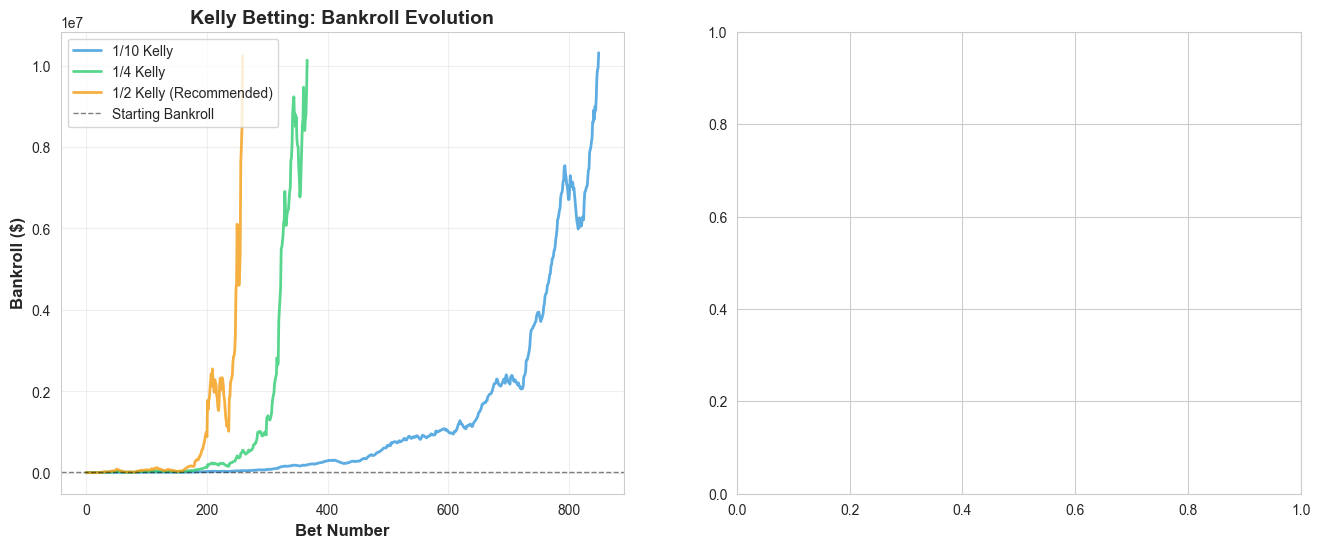

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Bankroll evolution for different Kelly fractions
ax1 = axes[0]
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c', '#9b59b6']
labels = ['1/10 Kelly', '1/4 Kelly', '1/2 Kelly (Recommended)', '3/4 Kelly', 'Full Kelly']

for result, color, label in zip(kelly_results, colors, labels):
    ax1.plot(result['bankroll_history'], linewidth=2, color=color, label=label, alpha=0.8)

ax1.axhline(10000, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Starting Bankroll')
ax1.set_xlabel('Bet Number', fontsize=12, fontweight='bold')
ax1.set_ylabel('Bankroll ($)', fontsize=12, fontweight='bold')
ax1.set_title('Kelly Betting: Bankroll Evolution', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10, loc='best')
ax1.grid(True, alpha=0.3)

# Plot 2: Risk vs Return
ax2 = axes[1]
returns = [r['total_return'] for r in kelly_results]
drawdowns = [r['max_drawdown_pct'] for r in kelly_results]

scatter = ax2.scatter(drawdowns, returns, s=200, c=colors, alpha=0.7, edgecolor='black', linewidth=2)

for i, (dd, ret, label) in enumerate(zip(drawdowns, returns, labels)):
    ax2.annotate(label, (dd, ret), xytext=(5, 5), textcoords='offset points', 
                fontsize=10, fontweight='bold')

ax2.set_xlabel('Maximum Drawdown (%)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Total Return (%)', fontsize=12, fontweight='bold')
ax2.set_title('Kelly Betting: Risk vs Return Trade-off', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figs/kelly_criterion_analysis.png', dpi=300, bbox_inches='tight')
print("\n✓ Saved: kelly_criterion_analysis.png")
plt.show()

## 5. Recommendation

**For tennis betting:**
- **1/4 Kelly (conservative):** Best for learning, minimal drawdown
- **1/2 Kelly (recommended):** Industry standard, good growth with manageable risk
- **Full Kelly:** Maximum growth but 40-50% drawdowns possible - NOT recommended

**Key insight:** Fractional Kelly protects against model uncertainty and estimation errors.

In [33]:
# Find optimal Kelly multiplier (best Sharpe-like metric)
print("\n" + "="*80)
print("RECOMMENDATION")
print("="*80)

# Calculate return/drawdown ratio for each
for result, label in zip(kelly_results, labels):
    ratio = result['total_return'] / result['max_drawdown_pct'] if result['max_drawdown_pct'] > 0 else 0
    print(f"\n{label}:")
    print(f"  Total return: {result['total_return']:.1f}%")
    print(f"  Max drawdown: {result['max_drawdown_pct']:.1f}%")
    print(f"  Return/Risk ratio: {ratio:.2f}")

print("\n" + "="*80)
print("✓ Kelly analysis complete!")
print("="*80)


RECOMMENDATION

1/10 Kelly:
  Total return: 103052.8%
  Max drawdown: 26.5%
  Return/Risk ratio: 3886.16

1/4 Kelly:
  Total return: 101224.1%
  Max drawdown: 54.3%
  Return/Risk ratio: 1864.27

1/2 Kelly (Recommended):
  Total return: 102308.1%
  Max drawdown: 80.4%
  Return/Risk ratio: 1273.20

✓ Kelly analysis complete!
